In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import sys, os, glob, json
from pathlib import Path

print("Python:", sys.version.split()[0])

# 1) Librerías y GPU
try:
    import torch, torchvision
    print("torch:", torch.__version__, "| torchvision:", torchvision.__version__)
    print("GPU disponible:", torch.cuda.is_available(),
          "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "sin GPU")
except ImportError as e:
    print("Falta librería:", e)
try:
    import timm; print("timm instalado:", timm.__version__)
except ImportError:
    print("timm: no instalado")

# 2) ¿Existen los crops localmente y en Drive?
CROPS = Path("/content/crops")
print("\n/content/crops existe:", CROPS.exists())
if CROPS.exists():
    for s in ["train", "val", "test"]:
        n = len(list((CROPS / s).rglob("*.jpg")))
        print(f"  {s}: {n} imágenes")
DRIVE = Path("/content/drive/MyDrive")
print("Drive montado:", DRIVE.exists())
print("crops_cardd.zip en Drive:", list(DRIVE.rglob("crops_cardd.zip"))[:3] if DRIVE.exists() else "n/a")

# 3) Checkpoints existentes (en Colab y en Drive)
patrones = ["*.pt", "*.pth", "*.ckpt", "*.safetensors"]
encontrados = []
for base in [Path("/content"), DRIVE]:
    if base.exists():
        for pat in patrones:
            encontrados += [p for p in base.rglob(pat)
                            if "site-packages" not in str(p) and ".Trash" not in str(p)]
print("\nCheckpoints encontrados:", len(encontrados))
for p in encontrados[:15]:
    print(f"  {p}  ({os.path.getsize(p)/1e6:.1f} MB)")

# 4) Variables del notebook que mencionó Jorge
for nombre in ["DATOS", "CLASES", "prueba", "evaluar", "RESULTADOS", "model"]:
    print(f"variable '{nombre}':", "existe" if nombre in globals() else "no existe")

Python: 3.13.15
torch: 2.11.0+cu130 | torchvision: 0.26.0+cu130
GPU disponible: True | Tesla T4
timm instalado: 1.0.30

/content/crops existe: False
Drive montado: True
crops_cardd.zip en Drive: [PosixPath('/content/drive/MyDrive/IA Generativa/crops_cardd.zip')]

Checkpoints encontrados: 0
variable 'DATOS': no existe
variable 'CLASES': no existe
variable 'prueba': no existe
variable 'evaluar': no existe
variable 'RESULTADOS': no existe
variable 'model': no existe


# restaurar los crops desde el zip

Dónde: celda nueva en el notebook actual. Descomprime en el disco local de Colab (no en Drive) y verifica los conteos.

In [3]:
import shutil
from pathlib import Path

ZIP = Path("/content/drive/MyDrive/IA Generativa/crops_cardd.zip")
DESTINO = Path("/content/crops")

assert ZIP.exists(), "No encuentro el zip, revisa la ruta"
shutil.rmtree(DESTINO, ignore_errors=True)
shutil.unpack_archive(str(ZIP), str(DESTINO))

print("Contenido de /content/crops:", sorted(p.name for p in DESTINO.iterdir()))
for s in ["train", "val", "test"]:
    clases = sorted(p.name for p in (DESTINO / s).iterdir() if p.is_dir())
    n = len(list((DESTINO / s).rglob("*.jpg")))
    print(f"{s}: {n} imágenes | clases: {clases}")

Contenido de /content/crops: ['metadata.csv', 'test', 'train', 'val']
train: 5878 imágenes | clases: ['crack', 'dent', 'glass_shatter', 'lamp_broken', 'scratch', 'tire_flat']
val: 1667 imágenes | clases: ['crack', 'dent', 'glass_shatter', 'lamp_broken', 'scratch', 'tire_flat']
test: 758 imágenes | clases: ['crack', 'dent', 'glass_shatter', 'lamp_broken', 'scratch', 'tire_flat']


# transformaciones, DataLoaders y pesos de clase

Este bloque deja listo todo lo necesario para entrenar, sin entrenar todavía. No toca test: solo lo definimos para usarlo al final.

Decisiones (explicables en el informe):

Train usa augmentation suave: volteo horizontal, rotación pequeña y variación leve de color. Val y test no llevan augmentation.
Todos terminan con Resize((224,224)) directo y la normalización ImageNet, igual que el contrato con Jorge.
Desbalance: pesos de clase inversamente proporcionales a la frecuencia en train, aplicados en la loss. No usamos sampler ponderado a la vez, para no corregir dos veces.

In [4]:
import torch, random, numpy as np
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from collections import Counter

# --- Semillas (reproducibilidad) ---
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

CROPS = "/content/crops"
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
IMG = 224
BATCH = 32
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# --- Transformaciones ---
tf_train = transforms.Compose([
    transforms.Resize((IMG, IMG)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
tf_eval = transforms.Compose([          # esta es la misma que usará app.py
    transforms.Resize((IMG, IMG)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

# --- Datasets y DataLoaders ---
ds_train = datasets.ImageFolder(f"{CROPS}/train", transform=tf_train)
ds_val   = datasets.ImageFolder(f"{CROPS}/val",   transform=tf_eval)
ds_test  = datasets.ImageFolder(f"{CROPS}/test",  transform=tf_eval)   # NO se usa hasta el final

CLASES = ds_train.classes
assert CLASES == ds_val.classes == ds_test.classes, "El orden de clases difiere entre conjuntos"
print("Clases (índice = salida del modelo):", {i: c for i, c in enumerate(CLASES)})

dl_train = DataLoader(ds_train, batch_size=BATCH, shuffle=True,  num_workers=2, pin_memory=True)
dl_val   = DataLoader(ds_val,   batch_size=BATCH, shuffle=False, num_workers=2, pin_memory=True)
dl_test  = DataLoader(ds_test,  batch_size=BATCH, shuffle=False, num_workers=2, pin_memory=True)

# --- Pesos de clase (inverso de la frecuencia en train) ---
conteo = Counter(ds_train.targets)
n_total, n_clases = len(ds_train), len(CLASES)
pesos = torch.tensor([n_total / (n_clases * conteo[i]) for i in range(n_clases)], dtype=torch.float32)

print("\nImágenes por clase en train y peso asignado:")
for i, c in enumerate(CLASES):
    print(f"  {c:14s} n={conteo[i]:5d}  peso={pesos[i]:.2f}")
print(f"\nTamaños -> train: {len(ds_train)} | val: {len(ds_val)} | test: {len(ds_test)} | device: {device}")

Clases (índice = salida del modelo): {0: 'crack', 1: 'dent', 2: 'glass_shatter', 3: 'lamp_broken', 4: 'scratch', 5: 'tire_flat'}

Imágenes por clase en train y peso asignado:
  crack          n=  477  peso=2.05
  dent           n= 1756  peso=0.56
  glass_shatter  n=  475  peso=2.06
  lamp_broken    n=  494  peso=1.98
  scratch        n= 2451  peso=0.40
  tire_flat      n=  225  peso=4.35

Tamaños -> train: 5878 | val: 1667 | test: 758 | device: cuda


# modelo, loss, optimizer y prueba de 1 época

Todavía no entrenamos en serio. Con una época confirmamos que el modelo carga, la GPU responde y la loss baja.

Decisiones (explicables en el informe):

Transfer learning: partimos de EfficientNet-B0 preentrenado en ImageNet, que ya sabe detectar bordes, texturas y formas.
Capa reemplazada: solo model.classifier[1], que pasa de 1000 salidas a 6. Es exactamente lo que hace la app de Jorge.
Qué entrenamos: por ahora todas las capas con learning rate bajo (1e-4), que es estable y simple. No congelamos nada para evitar un tuning excesivo.
Loss: CrossEntropyLoss con los pesos de clase del paso 3.
Optimizer: AdamW con lr=1e-4.

In [5]:
import torch.nn as nn, time
from torchvision import models

# --- Modelo: EfficientNet-B0 preentrenado en ImageNet (torchvision) ---
model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
in_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(in_features, len(CLASES))   # 1000 -> 6 salidas
model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=pesos.to(device))
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)

print("Capa final:", model.classifier[1])
print("Parámetros entrenables:", sum(p.numel() for p in model.parameters() if p.requires_grad))

def correr_epoca(dl, entrenar):
    model.train() if entrenar else model.eval()
    perdida, aciertos, total = 0.0, 0, 0
    with torch.set_grad_enabled(entrenar):
        for x, y in dl:
            x, y = x.to(device), y.to(device)
            salida = model(x)
            loss = criterion(salida, y)
            if entrenar:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            perdida += loss.item() * x.size(0)
            aciertos += (salida.argmax(1) == y).sum().item()
            total += x.size(0)
    return perdida / total, aciertos / total

# --- Prueba de 1 época (solo train y val; test NO se toca) ---
t0 = time.time()
tr_loss, tr_acc = correr_epoca(dl_train, entrenar=True)
va_loss, va_acc = correr_epoca(dl_val, entrenar=False)
print(f"\nÉpoca de prueba ({time.time()-t0:.0f}s)")
print(f"  train: loss={tr_loss:.3f} acc={tr_acc:.3f}")
print(f"  val:   loss={va_loss:.3f} acc={va_acc:.3f}")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 74.7MB/s]


Capa final: Linear(in_features=1280, out_features=6, bias=True)
Parámetros entrenables: 4015234

Época de prueba (46s)
  train: loss=0.798 acc=0.624
  val:   loss=0.487 acc=0.837


# entrenamiento completo con early stopping

Decisiones:

Se recrea el modelo desde cero (la época de prueba lo modificó).
Máximo 25 épocas, con early stopping: se detiene si el Macro F1 de val no mejora en 5 épocas. Uso Macro F1 y no accuracy para elegir la mejor época, porque con este desbalance la accuracy favorece a scratch y dent.
Scheduler ReduceLROnPlateau suave: baja el learning rate si val se estanca. Es lo único extra.
Mejor checkpoint guardado en Drive como state_dict, según el contrato. Test no se toca.

In [6]:
import copy, time
import torch.nn as nn
from torchvision import models
from sklearn.metrics import f1_score
from pathlib import Path

# --- Modelo nuevo desde cero ---
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
model.classifier[1] = nn.Linear(model.classifier[1].in_features, len(CLASES))
model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=pesos.to(device))
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=2)

MAX_EPOCAS, PACIENCIA = 25, 5
CKPT_DIR = Path("/content/drive/MyDrive/IA Generativa/checkpoints")
CKPT_DIR.mkdir(parents=True, exist_ok=True)
CKPT = CKPT_DIR / "efficientnet_b0_best.pt"

def correr_epoca(dl, entrenar):
    model.train() if entrenar else model.eval()
    perdida, total, preds, reales = 0.0, 0, [], []
    with torch.set_grad_enabled(entrenar):
        for x, y in dl:
            x, y = x.to(device), y.to(device)
            salida = model(x)
            loss = criterion(salida, y)
            if entrenar:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            perdida += loss.item() * x.size(0); total += x.size(0)
            preds += salida.argmax(1).cpu().tolist(); reales += y.cpu().tolist()
    acc = float(np.mean(np.array(preds) == np.array(reales)))
    f1 = f1_score(reales, preds, average="macro")
    return perdida / total, acc, f1

hist = {"tr_loss": [], "va_loss": [], "tr_acc": [], "va_acc": [], "va_f1": []}
mejor_f1, mejor_epoca, sin_mejora = -1.0, 0, 0

for ep in range(1, MAX_EPOCAS + 1):
    t0 = time.time()
    tr_loss, tr_acc, _ = correr_epoca(dl_train, True)
    va_loss, va_acc, va_f1 = correr_epoca(dl_val, False)
    scheduler.step(va_f1)
    for k, v in zip(hist, [tr_loss, va_loss, tr_acc, va_acc, va_f1]):
        hist[k].append(v)

    marca = ""
    if va_f1 > mejor_f1:
        mejor_f1, mejor_epoca, sin_mejora = va_f1, ep, 0
        torch.save(model.state_dict(), CKPT)      # solo el state_dict
        marca = "  <- mejor, guardado"
    else:
        sin_mejora += 1
    print(f"Época {ep:2d} ({time.time()-t0:.0f}s) | train loss {tr_loss:.3f} acc {tr_acc:.3f} | "
          f"val loss {va_loss:.3f} acc {va_acc:.3f} F1 {va_f1:.3f} | lr {optimizer.param_groups[0]['lr']:.0e}{marca}")
    if sin_mejora >= PACIENCIA:
        print(f"\nEarly stopping en la época {ep}."); break

print(f"\nMejor época: {mejor_epoca} | mejor F1 macro en val: {mejor_f1:.3f}")
print("Checkpoint:", CKPT, f"({CKPT.stat().st_size/1e6:.1f} MB)")

Época  1 (43s) | train loss 0.798 acc 0.624 | val loss 0.487 acc 0.837 F1 0.855 | lr 1e-04  <- mejor, guardado
Época  2 (43s) | train loss 0.245 acc 0.870 | val loss 0.305 acc 0.897 F1 0.920 | lr 1e-04  <- mejor, guardado
Época  3 (45s) | train loss 0.156 acc 0.913 | val loss 0.260 acc 0.908 F1 0.928 | lr 1e-04  <- mejor, guardado
Época  4 (43s) | train loss 0.123 acc 0.929 | val loss 0.228 acc 0.917 F1 0.937 | lr 1e-04  <- mejor, guardado
Época  5 (43s) | train loss 0.101 acc 0.940 | val loss 0.231 acc 0.914 F1 0.935 | lr 1e-04
Época  6 (43s) | train loss 0.075 acc 0.953 | val loss 0.206 acc 0.927 F1 0.947 | lr 1e-04  <- mejor, guardado
Época  7 (43s) | train loss 0.058 acc 0.967 | val loss 0.201 acc 0.933 F1 0.948 | lr 1e-04  <- mejor, guardado
Época  8 (43s) | train loss 0.056 acc 0.967 | val loss 0.264 acc 0.908 F1 0.927 | lr 1e-04
Época  9 (43s) | train loss 0.052 acc 0.968 | val loss 0.205 acc 0.934 F1 0.947 | lr 1e-04
Época 10 (43s) | train loss 0.046 acc 0.973 | val loss 0.223 

# curvas de entrenamiento

Aún sin tocar test. Esto genera las curvas de loss y accuracy que pediste para el notebook, y las guarda como imagen.

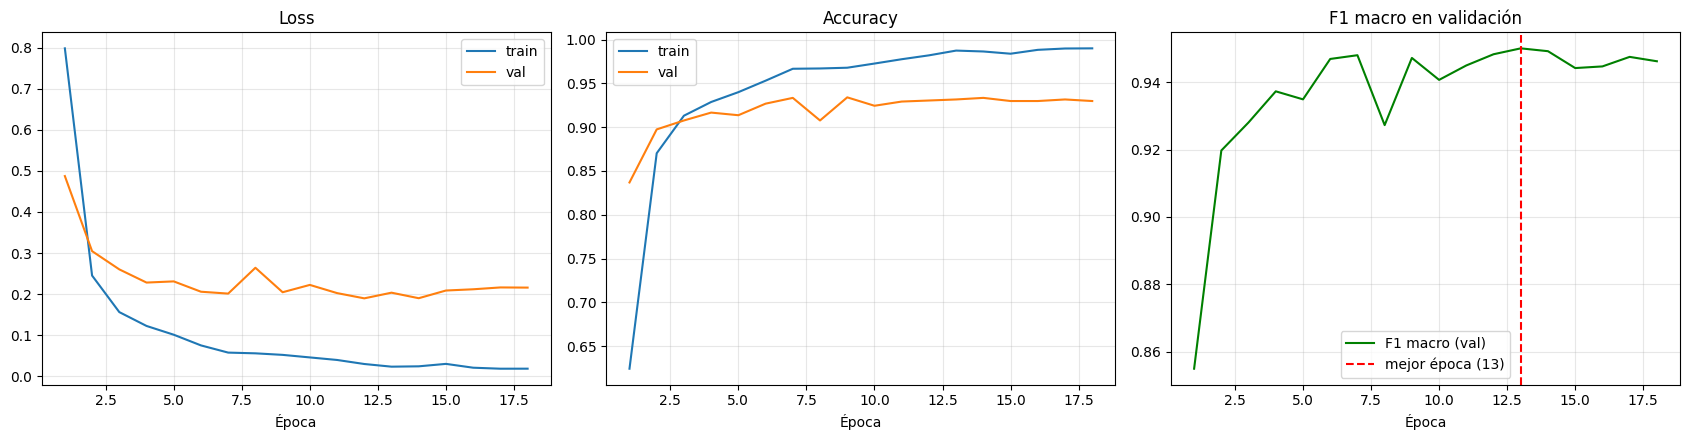

In [7]:
import matplotlib.pyplot as plt

ep = range(1, len(hist["tr_loss"]) + 1)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

ax[0].plot(ep, hist["tr_loss"], label="train"); ax[0].plot(ep, hist["va_loss"], label="val")
ax[0].set_title("Loss"); ax[0].set_xlabel("Época"); ax[0].legend()

ax[1].plot(ep, hist["tr_acc"], label="train"); ax[1].plot(ep, hist["va_acc"], label="val")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("Época"); ax[1].legend()

ax[2].plot(ep, hist["va_f1"], color="green", label="F1 macro (val)")
ax[2].axvline(mejor_epoca, color="red", linestyle="--", label=f"mejor época ({mejor_epoca})")
ax[2].set_title("F1 macro en validación"); ax[2].set_xlabel("Época"); ax[2].legend()

for a in ax: a.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/IA Generativa/checkpoints/curvas_entrenamiento.png", dpi=150)
plt.show()

# evaluación final en test (una sola vez)

Condición: al ejecutar esto, el modelo queda cerrado. Si cambias algo después de ver el resultado de test, esa evaluación deja de ser honesta. Si el resultado no te gusta, se reporta tal cual.

Qué calcula:

Accuracy, balanced accuracy, precision, recall y F1 macro.
Métricas por clase y matriz de confusión (guardada como imagen).
Error crítico graves→leves, igual que el de CLIP: graves = crack, glass_shatter, lamp_broken, tire_flat; leves = dent, scratch.
Comparación con CLIP: accuracy 53,0 %, balanced accuracy 73,5 %, F1 macro 61,0 %, graves→leves 14/226 = 6,2 %.

Accuracy:          0.947   (CLIP 0.530)
Balanced accuracy: 0.956   (CLIP 0.735)
Precision macro:   0.963
Recall macro:      0.956
F1 macro:          0.959   (CLIP 0.610)

                precision    recall  f1-score   support

        crack      0.922     0.870     0.895        54
         dent      0.936     0.936     0.936       234
glass_shatter      1.000     0.986     0.993        71
  lamp_broken      0.986     1.000     0.993        69
      scratch      0.934     0.943     0.938       298
    tire_flat      1.000     1.000     1.000        32

     accuracy                          0.947       758
    macro avg      0.963     0.956     0.959       758
 weighted avg      0.947     0.947     0.947       758

Graves predichos como leves: 7/226 = 3.1%   (CLIP 14/226 = 6.2%)


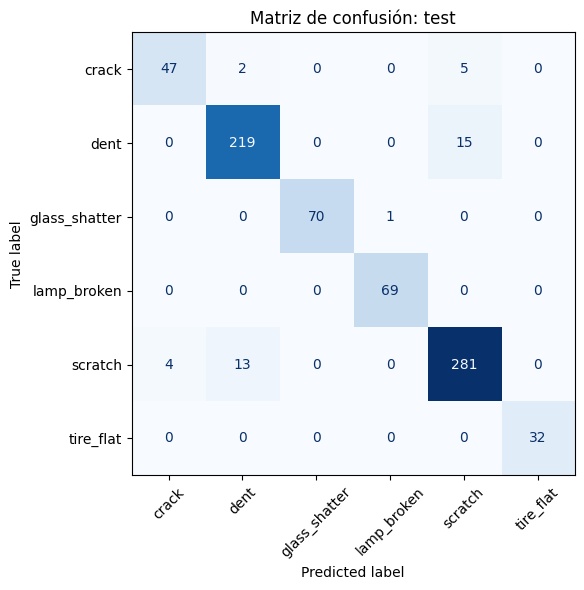

[[ 47   2   0   0   5   0]
 [  0 219   0   0  15   0]
 [  0   0  70   1   0   0]
 [  0   0   0  69   0   0]
 [  4  13   0   0 281   0]
 [  0   0   0   0   0  32]]


In [8]:
import numpy as np, torch, torch.nn as nn
import matplotlib.pyplot as plt
from torchvision import models
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)

# --- Cargar el mejor checkpoint en un modelo nuevo ---
m = models.efficientnet_b0(weights=None)
m.classifier[1] = nn.Linear(m.classifier[1].in_features, len(CLASES))
m.load_state_dict(torch.load(CKPT, map_location="cpu"))
m = m.to(device).eval()

# --- Predicciones sobre TEST (única vez) ---
preds, reales, confs = [], [], []
with torch.no_grad():
    for x, y in dl_test:
        p = torch.softmax(m(x.to(device)), dim=1).cpu()
        preds += p.argmax(1).tolist(); reales += y.tolist(); confs += p.max(1).values.tolist()
preds, reales, confs = np.array(preds), np.array(reales), np.array(confs)

# --- Métricas globales ---
acc = accuracy_score(reales, preds)
bal = balanced_accuracy_score(reales, preds)
pr, rc, f1, _ = precision_recall_fscore_support(reales, preds, average="macro", zero_division=0)
print(f"Accuracy:          {acc:.3f}   (CLIP 0.530)")
print(f"Balanced accuracy: {bal:.3f}   (CLIP 0.735)")
print(f"Precision macro:   {pr:.3f}")
print(f"Recall macro:      {rc:.3f}")
print(f"F1 macro:          {f1:.3f}   (CLIP 0.610)")

# --- Por clase ---
print("\n", classification_report(reales, preds, target_names=CLASES, digits=3, zero_division=0))

# --- Error crítico graves -> leves ---
graves = [CLASES.index(c) for c in ["crack", "glass_shatter", "lamp_broken", "tire_flat"]]
leves = [CLASES.index(c) for c in ["dent", "scratch"]]
es_grave = np.isin(reales, graves)
grave_a_leve = es_grave & np.isin(preds, leves)
print(f"Graves predichos como leves: {grave_a_leve.sum()}/{es_grave.sum()} = "
      f"{100*grave_a_leve.sum()/es_grave.sum():.1f}%   (CLIP 14/226 = 6.2%)")

# --- Matriz de confusión ---
cm = confusion_matrix(reales, preds)
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(cm, display_labels=CLASES).plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
ax.set_title("Matriz de confusión: test")
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/IA Generativa/checkpoints/matriz_confusion_test.png", dpi=150)
plt.show()
print(cm)

# errores con alta confianza y ejemplos mal clasificados

Es lo que falta de tu análisis (errores con alta confianza). Usa las variables de la celda anterior.

Errores: 40 de 758
Confianza media en aciertos: 0.981 | en errores: 0.849
Errores con confianza >= 0.90: 21 de 40


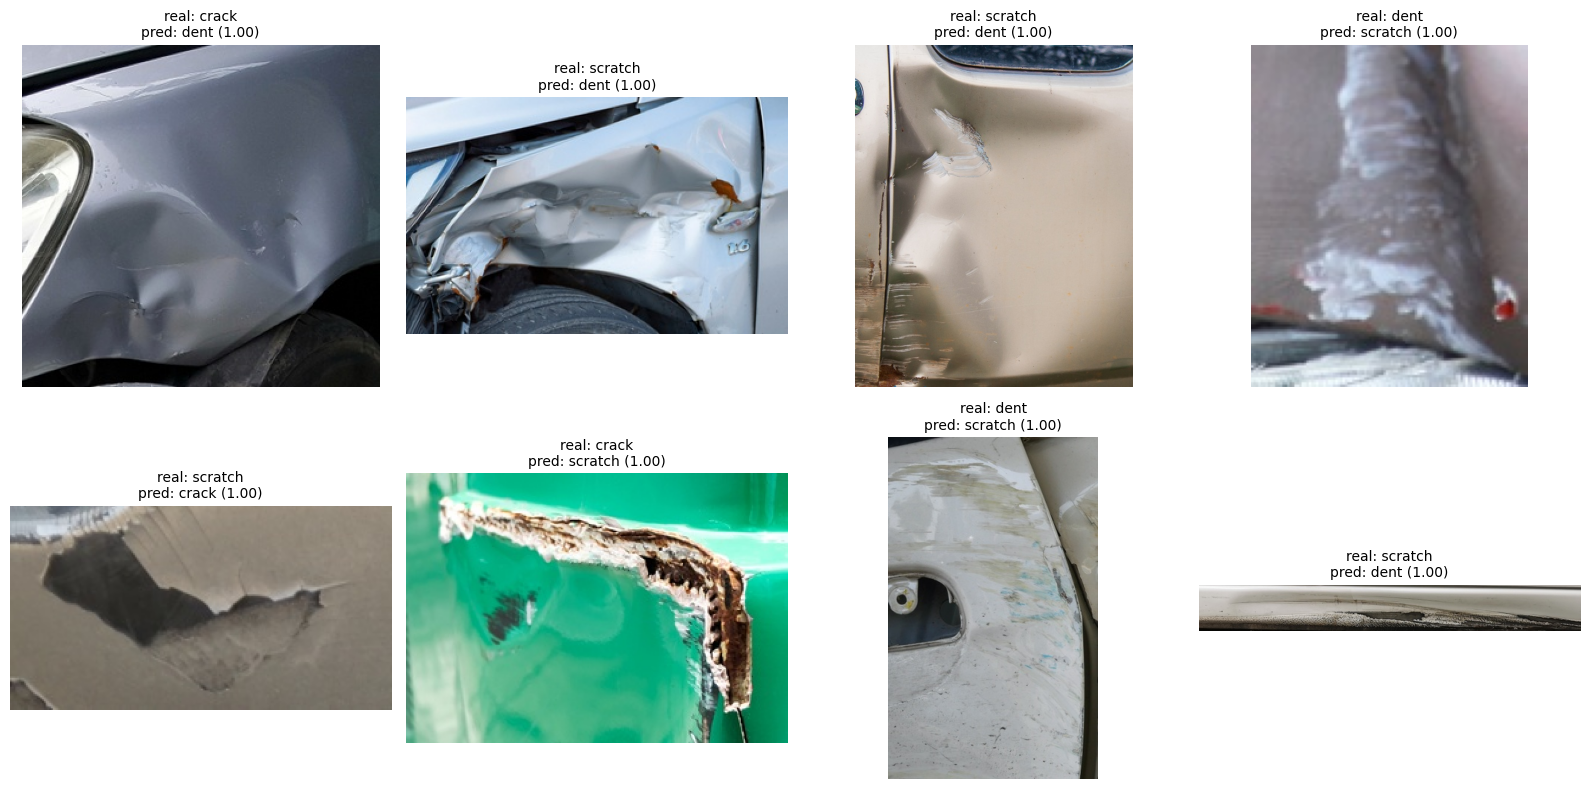

In [9]:
import random
from PIL import Image

err = np.where(preds != reales)[0]
print(f"Errores: {len(err)} de {len(reales)}")
print(f"Confianza media en aciertos: {confs[preds == reales].mean():.3f} | en errores: {confs[err].mean():.3f}")
alta = err[confs[err] >= 0.90]
print(f"Errores con confianza >= 0.90: {len(alta)} de {len(err)}")

# Los 8 errores más seguros de sí mismos
top = err[np.argsort(-confs[err])][:8]
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, i in zip(axes.ravel(), top):
    ruta = ds_test.samples[i][0]
    ax.imshow(Image.open(ruta).convert("RGB"))
    ax.set_title(f"real: {CLASES[reales[i]]}\npred: {CLASES[preds[i]]} ({confs[i]:.2f})", fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/IA Generativa/checkpoints/errores_alta_confianza.png", dpi=150)
plt.show()

# exportación (model.pt + classes.json)

Exportamos exactamente el checkpoint de la época 13, que es el que evaluaste en test. No se reentrena nada.

In [10]:
import json, shutil, torch, torchvision
from pathlib import Path

EXPORT = Path("/content/drive/MyDrive/IA Generativa/export")
EXPORT.mkdir(parents=True, exist_ok=True)

# 1) model.pt: solo el state_dict (copia del mejor checkpoint evaluado)
sd = torch.load(CKPT, map_location="cpu")
torch.save(sd, EXPORT / "model.pt")

# 2) classes.json: lista ordenada según el índice de salida
with open(EXPORT / "classes.json", "w") as f:
    json.dump(CLASES, f, indent=2)

# 3) model_info.json: ficha técnica para el equipo
info = {
    "arquitectura": "torchvision.models.efficientnet_b0(weights=None); classifier[1]=nn.Linear(1280, 6)",
    "formato_model_pt": "state_dict",
    "clases_en_orden": CLASES,
    "input": {"resize": [224, 224], "normalize_mean": [0.485, 0.456, 0.406],
              "normalize_std": [0.229, 0.224, 0.225], "color": "RGB", "augmentation_en_inferencia": False},
    "versiones": {"torch": torch.__version__, "torchvision": torchvision.__version__},
    "entrenamiento": {"mejor_epoca": int(mejor_epoca), "f1_macro_val": round(float(mejor_f1), 3),
                      "optimizer": "AdamW lr=1e-4 wd=1e-4", "loss": "CrossEntropy con pesos de clase", "seed": 42},
    "test": {"accuracy": 0.947, "balanced_accuracy": 0.956, "f1_macro": 0.959, "graves_a_leves": "7/226"},
}
with open(EXPORT / "model_info.json", "w") as f:
    json.dump(info, f, indent=2, ensure_ascii=False)

for p in sorted(EXPORT.iterdir()):
    print(f"{p.name}  ({p.stat().st_size/1e6:.2f} MB)")
print("classes.json:", json.load(open(EXPORT / "classes.json")))

classes.json  (0.00 MB)
model.pt  (16.34 MB)
model_info.json  (0.00 MB)
classes.json: ['crack', 'dent', 'glass_shatter', 'lamp_broken', 'scratch', 'tire_flat']


# prueba de recarga en sesión limpia

Hay que comprobar que model.pt funciona sin nada de lo que existe en la memoria de este notebook. Replica lo que hace la app de Jorge y compara con la predicción del modelo entrenado.

1) Reinicia el entorno: menú Entorno de ejecución → Reiniciar sesión. Así se borran todas las variables.

2) Monta Drive (celda nueva):

In [11]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [12]:
import json, zipfile, torch, torch.nn as nn
from pathlib import Path
from PIL import Image
from torchvision import models, transforms

EXPORT = Path("/content/drive/MyDrive/IA Generativa/export")
CLASES = json.load(open(EXPORT / "classes.json"))

# Arquitectura tal como la construye la app de Jorge
model = models.efficientnet_b0(weights=None)
model.classifier[1] = nn.Linear(model.classifier[1].in_features, len(CLASES))
model.load_state_dict(torch.load(EXPORT / "model.pt", map_location="cpu"))
model.eval()

prep = transforms.Compose([
    transforms.Resize((224, 224)), transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

def predict(img):
    with torch.no_grad():
        p = torch.softmax(model(prep(img.convert("RGB")).unsqueeze(0)), dim=1)[0]
    i = int(p.argmax())
    return CLASES[i], float(p[i])

# Probar con 1 imagen real de cada clase del conjunto de test
with zipfile.ZipFile("/content/drive/MyDrive/IA Generativa/crops_cardd.zip") as z:
    nombres = [n for n in z.namelist() if n.startswith("test/") and n.endswith(".jpg")]
    for clase in CLASES:
        n = next(x for x in nombres if x.split("/")[1] == clase)
        with z.open(n) as f:
            img = Image.open(f); img.load()
        pred, conf = predict(img)
        print(f"{'OK ' if pred == clase else 'ERR'} real: {clase:14s} pred: {pred:14s} conf: {conf:.3f}")

ERR real: crack          pred: dent           conf: 1.000
OK  real: dent           pred: dent           conf: 0.990
OK  real: glass_shatter  pred: glass_shatter  conf: 1.000
OK  real: lamp_broken    pred: lamp_broken    conf: 0.997
OK  real: scratch        pred: scratch        conf: 0.999
OK  real: tire_flat      pred: tire_flat      conf: 1.000


In [13]:
import zipfile, numpy as np, io

with zipfile.ZipFile("/content/drive/MyDrive/IA Generativa/crops_cardd.zip") as z:
    nombres = [n for n in z.namelist() if n.startswith("test/") and n.endswith(".jpg")]
    aciertos, graves, g2l = 0, 0, 0
    graves_set, leves_set = {"crack","glass_shatter","lamp_broken","tire_flat"}, {"dent","scratch"}
    for n in nombres:
        real = n.split("/")[1]
        img = Image.open(io.BytesIO(z.read(n))); img.load()
        pred, _ = predict(img)
        aciertos += (pred == real)
        if real in graves_set:
            graves += 1; g2l += (pred in leves_set)

print(f"Imágenes: {len(nombres)} | accuracy: {aciertos/len(nombres):.3f} | graves->leves: {g2l}/{graves}")

Imágenes: 758 | accuracy: 0.947 | graves->leves: 7/226
